# TCN e TCN-Attention com e sem pré-processamento/FE × baselines ARIMA, SVR e MLP
**Datasets:** Kaggle *Time Series Forecasting of Solar Energy* (base do artigo do TCN), e INMET de São Paulo, Florianópolis, Salvador e Fortaleza (base do artigo do professor). Todos no **mesmo período, 2016–2020**.

**Referências**
- **[TCN]** Honnurvali et al., *A TCN-Attention Model for High-Accuracy Solar Energy Generation Forecasting*, IEEE OAJPE, v. 13, pp. 690–701, 2026.
- **[MDPI]** de O. Santos Jr. et al., *Solar Irradiance Forecasting Using Dynamic Ensemble Selection*, Appl. Sci. 12, 3510, 2022. Código: github.com/domingos108/solar_forecasting

| Item | Escolha | Fonte |
|---|---|---|
| Períodos | 2016–2020 em todos: cidades 01/01/2016–31/12/2020; Kaggle 01/01/2016–03/08/2020 (a série termina aí) | seção 1 |
| Split | 60/20/20 cronológico em todos os datasets: o teste é o último ~1 ano de cada série | [MDPI] Sec. 5, p. 8 |
| Baselines | ARIMA (AutoARIMA stepwise de Hyndman), SVR e MLP com o código do professor reimplementado e a Tabela 1 | [MDPI] Tabela 1, p. 8 |
| TCN e TCN-Attention | Janela: 48 no Kaggle (artigo) e 12 nas cidades (professor); conv. causal dilatada, ReLU, atenção aditiva, saída σ, MSE, Adam | [TCN] Eq. 2–8, Alg. 1, Fig. 6 |
| SEM pré-proc./FE | Série bruta, só Min-Max | — |
| COM pré-proc./FE | Faltantes, IQR, Min-Max, lags, médias móveis, ewm, interação com temperatura, binning, calendário e variáveis meteorológicas | [TCN] Sec. III–IV, Tabela 1, Fig. 2 |
| Métricas | RMSE, MAPE, MAE, ARV e IA na escala [0.1, 0.9] | [MDPI] Sec. 5.2 e Tabela 3 |
| Repetições | 10 execuções independentes | [MDPI] Sec. 5.3, p. 10 |
| Figuras | Boxplot do RMSE, diagrama de distância crítica (Friedman–Nemenyi) e real × TCN-Attention nos 150 primeiros pontos do teste | [MDPI] Figs. 4–12 |

**Retomada:** cada execução é gravada em `resultados_2016_2020/` assim que termina. Se a máquina cair, rode o notebook de novo e ele pula o que já foi feito.
**Sumário**
1. Datasets
2. Métricas
3. Baselines
   - 3.0 Pipeline do professor
   - 3.1 ARIMA
   - 3.2 SVR
   - 3.3 MLP
4. Preparação SEM e COM pré-processamento/FE
5. TCN e TCN-Attention
   - 5.1 Bloco residual causal
   - 5.2 Codificador TCN
   - 5.3 Atenção aditiva
   - 5.4 Modelos completos
   - 5.5 Conferência
   - 5.6 Treino
   - 5.7 Execução
6. Tabelas
7. Boxplot
8. Distância crítica
9. Real × previsto

In [1]:
# ============ CONFIGURAÇÃO ============
MODO_RAPIDO = False     # True = teste do código (2 execuções, 3 épocas). Para o experimento real: False
N_EXEC = 2 if MODO_RAPIDO else 10
MAX_EPOCAS = 3 if MODO_RAPIDO else 200

# Onde salvar os resultados. No Colab, para não perder nada se a sessão cair, use o Google Drive:
#   from google.colab import drive; drive.mount("/content/drive")
#   PASTA_RESULTADOS = "/content/drive/MyDrive/tcn_fe/resultados_2016_2020"
# No Colab, a pasta dados/ precisa estar ao lado do notebook (clone o repositório ou suba notebooks/dados/).
PASTA_RESULTADOS = "resultados_2016_2020"    # pasta nova: não mistura com os resultados do experimento só com 2020

# Períodos dos dados (seção 1). Os CSVs ficam em dados/; o notebook não acessa o portal do INMET.
# Para usar outros anos, gere os arquivos antes, da raiz do repositório: python ferramentas/baixar_inmet.py <anos>
# Mesmo período em todos os datasets: 2016–2020 (faltantes mantidos, como no carregador do professor).
ANOS_INMET = {"Sao Paulo":     range(2016, 2021),    # 2016–2020
              "Florianopolis": range(2016, 2021),    # 2016–2020
              "Salvador":      range(2016, 2021),    # 2016–2020
              "Fortaleza":     range(2016, 2021)}    # 2016–2020 (2019 tem uma falha de 73 dias)
INICIO_KAGGLE = "2016-01-01"                         # 2016 até o fim da série (03/08/2020)

In [2]:
%pip install -q statsforecast
import os, io, zipfile, urllib.request, urllib.parse, copy, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import ParameterGrid
from sklearn.base import clone
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from statsforecast.models import AutoARIMA
from scipy.stats import friedmanchisquare, rankdata
warnings.filterwarnings("ignore")

# Dados locais em dados/: CSVs do INMET (formato do repositório do professor) e solarenergy.csv do Kaggle.
# O código do professor está reimplementado abaixo; nada é baixado do repositório dele nem do portal do INMET.
DADOS = Path("dados"); DADOS.mkdir(exist_ok=True)

PASTA = Path(PASTA_RESULTADOS); (PASTA / "previsoes").mkdir(parents=True, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("dispositivo:", DEVICE, "| execuções:", N_EXEC)

Note: you may need to restart the kernel to use updated packages.
dispositivo: cuda | execuções: 10


## 1. Datasets
- **INMET:** cada ano é lido com `carregar_horas_solares`, a reimplementação de `tsf.load_data_solar_hours` do professor: horas de 09 a 21 UTC (06 a 18 locais), faltantes = 0, 13 amostras por dia. Depois os anos são concatenados.
- **Kaggle:** série `solar_mw` de `solarenergy.csv`, de 01/01/2016 a 03/08/2020, quando a série termina (40.225 h). A meteorologia só existe nas últimas 2920 h, então ela **não é usada**: o Kaggle entra sem variáveis exógenas nas duas condições.
- **Variáveis exógenas (só cidades, só COM FE):** temperatura, umidade, pressão, vento e chuva.
- **Por que 2016–2020:** é o mesmo período para todos os datasets, com 5 anos para cobrir a sazonalidade. Com 60/20/20, o treino cobre 2016–2018 (3 anos, os 12 meses repetidos 3 vezes; a célula abaixo confere), a validação é 2019 e o teste é **2020 inteiro** nas cidades. No Kaggle, o teste é set/2019–ago/2020.

| Estação | 2016 | 2017 | 2018 | 2019 | 2020 |
|---|---|---|---|---|---|
| São Paulo (A701) | 8,2% | 8,4% | 6,4% | 7,7% | 7,1% |
| Florianópolis (A806) | 7,4% | 8,5% | 9,1% | 10,1% | 7,2% |
| Salvador (A401) | 7,3% (falha de 21 dias) | 1,7% | 1,7% | 1,3% | 1,4% |
| Fortaleza (A305) | 13,2% | 1,5% | 4,3% | 26,7% (falha de 73 dias) | 1,0% |

Fração das horas de luz sem dado de radiação. Os faltantes viram 0, como no carregador do professor, e ficam na série. Falhas longas: Salvador 2016 (21 dias, no treino) e Fortaleza 2019 (73 dias, na validação). O resto são buracos de poucas horas, quase todos ao amanhecer. Os arquivos foram gerados a partir dos pacotes anuais do portal do INMET por `ferramentas/baixar_inmet.py`, no formato do repositório do professor. Conferido: o pacote de 2020 convertido fica idêntico, valor a valor, aos arquivos de 2020 dele.

In [3]:
def carregar_horas_solares(caminho, hora_min="0900 UTC", hora_max="2100 UTC"):
    # = tsf.load_data_solar_hours: lê o CSV do INMET, troca radiação faltante por 0 e mantém de 09 a 21 UTC
    df = pd.read_csv(caminho, sep=";", decimal=",", encoding="utf8")
    df["RADIACAO GLOBAL (Kj/m)"] = df["RADIACAO GLOBAL (Kj/m)"].fillna(0)
    df["Data"] = pd.to_datetime(df["Data"] + " " + df["Hora UTC"], format="%d/%m/%Y %H%M UTC")
    hora = lambda x: int(x.split(" ")[0])                       # = tsf.utc_hour_to_int ("0900 UTC" → 900)
    manter = df["Hora UTC"].apply(lambda x: hora(hora_min) <= hora(x) <= hora(hora_max))
    df = df[manter][["Data", "RADIACAO GLOBAL (Kj/m)"]].rename(columns={"RADIACAO GLOBAL (Kj/m)": "actual"})
    return df.set_index("Data")

INMET = {  # nome: início do nome do arquivo (o ano completa o nome, como no repositório do professor)
    "Sao Paulo":     "INMET_SE_SP_A701_SAO PAULO - MIRANTE",
    "Florianopolis": "INMET_S_SC_A806_FLORIANOPOLIS",
    "Salvador":      "INMET_NE_BA_A401_SALVADOR",
    "Fortaleza":     "INMET_NE_CE_A305_FORTALEZA",
}
PREFIXOS = {"temp": "TEMPERATURA DO AR - BULBO SECO", "umid": "UMIDADE RELATIVA DO AR",
            "pres": "PRESSAO ATMOSFERICA AO NIVEL", "vento": "VENTO, VELOCIDADE", "chuva": "PRECIPITACAO TOTAL"}

def carregar_inmet_ano(caminho):
    serie = carregar_horas_solares(caminho)                                # = tsf.load_data_solar_hours
    bruto = pd.read_csv(caminho, sep=";", decimal=",")
    bruto.index = pd.to_datetime(bruto["Data"] + " " + bruto["Hora UTC"], format="%d/%m/%Y %H%M UTC")
    exo = pd.DataFrame({k: pd.to_numeric(bruto[[c for c in bruto.columns if c.startswith(p)][0]], errors="coerce").to_numpy()
                        for k, p in PREFIXOS.items()}, index=bruto.index)
    exo = exo.where(exo > -9000).reindex(serie.index)
    return serie[["actual"]], exo

def carregar_inmet(nome):
    partes = []
    for ano in ANOS_INMET[nome]:
        caminho = DADOS / f"{INMET[nome]}_01-01-{ano}_A_31-12-{ano}.csv"
        if not caminho.exists():
            raise FileNotFoundError(f"{caminho} não existe. Gere-o, da raiz do repositório, com: python ferramentas/baixar_inmet.py {ano}")
        partes.append(carregar_inmet_ano(caminho))
    serie, exo = pd.concat([p[0] for p in partes]), pd.concat([p[1] for p in partes])
    assert serie.index.is_monotonic_increasing and not serie.index.duplicated().any()
    return serie, exo

def carregar_kaggle():
    arquivo = DADOS / "solarenergy.csv"
    if not arquivo.exists():               # só na primeira vez: baixa da API pública do Kaggle e guarda em dados/
        url = "https://www.kaggle.com/api/v1/datasets/download/chaitanyakumar12/time-series-forecasting-of-solar-energy"
        with zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())) as z:
            arquivo.write_bytes(z.read("solarenergy.csv"))
    df = pd.read_csv(arquivo, low_memory=False)
    df["Datetime"] = pd.to_datetime(df["Datetime"], format="%d/%m/%Y %H:%M")
    df = df.sort_values("Datetime").drop_duplicates("Datetime").set_index("Datetime").asfreq("h")
    df = df.loc[INICIO_KAGGLE:]
    serie = pd.to_numeric(df["solar_mw"], errors="coerce").to_frame("actual").interpolate().ffill()   # 54 h faltantes
    exo = pd.DataFrame(index=serie.index)          # sem meteorologia: ela só existe nas últimas 2920 h da série
    return serie, exo

DATASETS = {"Kaggle": dict(zip(["serie", "exo"], carregar_kaggle()), por_dia=24, inmet=False, lookback=48)}
for nome in INMET:
    DATASETS[nome] = dict(zip(["serie", "exo"], carregar_inmet(nome)), por_dia=13, inmet=True, lookback=12)

for nome, d in DATASETS.items():
    n = len(d["serie"]); d["n_te"] = d["n_va"] = int(0.2 * n); d["n_tr"] = n - 2 * d["n_te"]      # 60/20/20
    y, idx = d["serie"]["actual"], d["serie"].index
    meses_treino = idx[:d["n_tr"]].month.nunique()
    print(f"{nome:14s} n={n:6d} | treino {idx[0]:%d/%m/%Y}–{idx[d['n_tr'] - 1]:%d/%m/%Y} ({d['n_tr']}, {meses_treino}/12 meses) | "
          f"val {d['n_va']} | teste {idx[n - d['n_te']]:%d/%m/%Y}–{idx[-1]:%d/%m/%Y} ({d['n_te']}) | "
          f"média {y.mean():8.1f} | DP {y.std():8.1f} | exógenas: {d['exo'].shape[1]}")
    assert meses_treino == 12, f"{nome}: o treino não cobre os 12 meses"

Kaggle         n= 40225 | treino 01/01/2016–02/10/2018 (24135, 12/12 meses) | val 8045 | teste 02/09/2019–03/08/2020 (8045) | média  11185.1 | DP   2491.8 | exógenas: 0
Sao Paulo      n= 23751 | treino 01/01/2016–01/01/2019 (14251, 12/12 meses) | val 4750 | teste 01/01/2020–31/12/2020 (4750) | média   1322.9 | DP   1195.2 | exógenas: 5
Florianopolis  n= 23751 | treino 01/01/2016–01/01/2019 (14251, 12/12 meses) | val 4750 | teste 01/01/2020–31/12/2020 (4750) | média   1190.9 | DP   1085.6 | exógenas: 5
Salvador       n= 23751 | treino 01/01/2016–01/01/2019 (14251, 12/12 meses) | val 4750 | teste 01/01/2020–31/12/2020 (4750) | média   1417.1 | DP   1155.4 | exógenas: 5
Fortaleza      n= 23751 | treino 01/01/2016–01/01/2019 (14251, 12/12 meses) | val 4750 | teste 01/01/2020–31/12/2020 (4750) | média   1187.0 | DP    938.0 | exógenas: 5


## 2. Métricas (as do professor, na escala do artigo dele)
`metricas_professor` reimplementa `tsf.gerenerate_metric_results`, com as mesmas fórmulas:

| Métrica | Fórmula |
|---|---|
| RMSE | $\sqrt{\frac{1}{N}\sum (y_t-\hat y_t)^2}$ |
| MAPE | $\frac{100}{N}\sum \left|\frac{y_t-\hat y_t}{y_t}\right|$, descartando $y_t = 0$, como no código do professor |
| MAE | $\frac{1}{N}\sum \lvert y_t-\hat y_t\rvert$ |
| ARV | $\frac{\sum (y_t-\hat y_t)^2}{\sum (\hat y_t-\bar y)^2}$ |
| IA | $1-\frac{\sum (y_t-\hat y_t)^2}{\sum (\lvert\hat y_t-\bar y\rvert+\lvert y_t-\bar y\rvert)^2}$ |

**Escala:** antes do cálculo, real e previsto são levados para **[0.1, 0.9], com o mínimo e o máximo da série inteira** ([MDPI] Sec. 5, p. 8). É a convenção da Tabela 3 ([MDPI] p. 11) e só muda a escala do erro; o modelo não vê nada disso.

In [4]:
def metricas_professor(y_true, y_pred):
    # = tsf.gerenerate_metric_results (RMSE, MAPE, MAE, ARV, IA), com as mesmas fórmulas do código
    y_true, y_pred = np.asarray(y_true, float).ravel(), np.asarray(y_pred, float).ravel()
    erro = y_true - y_pred
    media = y_true.mean()
    nz = y_true != 0                                             # o MAPE do professor descarta os zeros
    return {"RMSE": np.sqrt(np.mean(erro ** 2)),
            "MAPE": np.mean(np.abs(erro[nz] / y_true[nz])) * 100,
            "MAE": np.mean(np.abs(erro)),
            "ARV": np.sum(erro ** 2) / np.sum((y_pred - media) ** 2),
            "IA": 1 - np.sum(erro ** 2) / np.sum((np.abs(y_pred - media) + np.abs(y_true - media)) ** 2)}

METRICAS = ["RMSE", "MAPE", "MAE", "ARV", "IA"]

def metricas(nome, y_true, y_pred):
    y = DATASETS[nome]["serie"]["actual"].to_numpy()
    mn, mx = y.min(), y.max()
    esc = lambda a: 0.1 + 0.8 * (np.asarray(a, float) - mn) / (mx - mn)
    r = metricas_professor(esc(y_true), esc(y_pred))
    return {k: float(r[k]) for k in METRICAS}

In [5]:
# Registro incremental: cada execução vai para resultados/metricas.csv e resultados/previsoes/*.npy
ARQ = PASTA / "metricas.csv"
RES = pd.read_csv(ARQ) if ARQ.exists() else pd.DataFrame(columns=["dataset", "modelo", "condicao", "execucao"] + METRICAS)

def feitas(nome, modelo, condicao):
    f = RES[(RES.dataset == nome) & (RES.modelo == modelo) & (RES.condicao == condicao)]
    return set(f.execucao.astype(int))

def registrar(nome, modelo, condicao, execucao, pred):
    global RES
    d = DATASETS[nome]; y = d["serie"]["actual"].to_numpy()
    pred = np.clip(np.asarray(pred, float), 0, None)
    assert len(pred) == d["n_te"], f"{modelo}: previsão com {len(pred)} pontos, esperado {d['n_te']}"
    np.save(PASTA / "previsoes" / f"{nome}__{modelo}__{condicao}__{execucao}.npy", pred)
    RES = pd.concat([RES, pd.DataFrame([{"dataset": nome, "modelo": modelo, "condicao": condicao,
                                         "execucao": execucao, **metricas(nome, y[-d["n_te"]:], pred)}])], ignore_index=True)
    RES.to_csv(ARQ, index=False)

## 3. Baselines: ARIMA, SVR e MLP (sempre SEM pré-processamento/FE, como no [MDPI])
O professor também não implementa os modelos do zero.
- **ARIMA:** ele usa o `auto.arima` do pacote `forecast`, em R. Aqui usamos o `AutoARIMA` do `statsforecast`, que é o mesmo método *stepwise* de Hyndman-Khandakar ([MDPI] ref. [65]).
- **SVR e MLP:** ele usa `sklearn.svm.SVR` e `sklearn.neural_network.MLPRegressor`, e aqui também. O que é dele, e está reimplementado abaixo, é o **pipeline em volta**: normalização, janelamento, busca em grade na validação e previsão no teste.

| Modelo | Seção | Implementação | Hiperparâmetros ([MDPI] Tabela 1, p. 8) | Determinístico? |
|---|---|---|---|---|
| ARIMA | 3.1 | `statsforecast.AutoARIMA` | ordem (p, d, q) escolhida pelo *stepwise* no treino | sim: 10 execuções iguais |
| SVR | 3.2 | `sklearn.svm.SVR` + pipeline do professor (3.0) | RBF; C ∈ {10, 100, 1000}; γ ∈ {0.1, 0.01, 0.001}; ε ∈ {0.1, 0.01, 0.001} | sim: 10 execuções iguais |
| MLP | 3.3 | `sklearn.neural_network.MLPRegressor` + pipeline do professor (3.0) | 1 camada oculta sigmoide, L-BFGS; {20, 50, 100} neurônios; tol ∈ {1e-3, 1e-4, 1e-5} | não: pesos iniciais mudam |

Que ARIMA e SVR repetem o mesmo resultado nas 10 execuções está no [MDPI] Sec. 5.4, p. 14.

### 3.0 Pipeline do professor (usado pelo SVR e pela MLP)
Reimplementação de `src/time_series_functions.py` (`tsf`) e `src/fit_predict_models.py` (`fpm`) do repositório github.com/domingos108/solar_forecasting. Cobre o caso do artigo dele: horizonte 1, sem exógenas, com normalização. Cada função indica a original que reproduz. As previsões foram comparadas com as do código original e são idênticas.

Fluxo de `modelo_unico` (= `fpm.single_model`):
1. Min-Max ajustado em treino + validação.
2. Janelas de 12 lags: `lag_12 … lag_1` → `actual`, o 13º valor.
3. `fit` nas janelas de treino e `predict` em todas.
4. Volta à escala original.

`busca_em_grade` (= `fpm.do_grid_search`) testa cada configuração da grade e escolhe a de menor RMSE médio na **validação**. `rodar_baseline` faz a busca uma vez e depois as 10 execuções no teste.

In [6]:
def criar_janelas(serie, lags):
    # = tsf.create_windowing + fpm.get_windowing: colunas lag_12 … lag_1 e 'actual' (o alvo é o 13º valor)
    s = pd.Series(serie)
    colunas = {f"lag_{i}": s.shift(i) for i in range(lags, 0, -1)}
    return pd.concat([pd.DataFrame(colunas), s.rename("actual")], axis=1).dropna()

def modelo_unico(serie, modelo, lags, n_te, n_va):
    # = fpm.single_model (horizonte 1, sem exógenas, normalize=True)
    y = serie["actual"].to_numpy(float)
    escala = MinMaxScaler().fit(y[:len(y) - n_te].reshape(-1, 1))     # ajustado em treino + validação, como no original
    z = escala.transform(y.reshape(-1, 1)).ravel()
    jan = criar_janelas(z, lags)
    n_ajuste = len(jan) - n_te - n_va                                   # = tsf.fit_sklearn_model
    X, alvo = jan.drop(columns="actual").to_numpy(), jan["actual"].to_numpy()
    modelo.fit(X[:n_ajuste], alvo[:n_ajuste])
    pred = escala.inverse_transform(modelo.predict(X).reshape(-1, 1)).ravel()   # = tsf.predict_sklearn_model
    return pred, y[-len(pred):], n_ajuste                               # previsões de todas as janelas (treino+val+teste)

def busca_em_grade(serie, modelo_base, grade, n_te, n_va, execs):
    # = fpm.do_grid_search: menor RMSE médio na VALIDAÇÃO (escala original), média de `execs` execuções por configuração
    melhor, melhor_rmse, melhor_lags = None, None, None
    for params in ParameterGrid(grade):
        params = dict(params); lags = params.pop("time_window")
        candidato = clone(modelo_base).set_params(**params)
        rmses = []
        for _ in range(execs):
            pred, real, n_ajuste = modelo_unico(serie, candidato, lags, n_te, n_va)
            val = slice(n_ajuste, len(pred) - n_te)
            rmses.append(metricas_professor(real[val], pred[val])["RMSE"])
        if melhor_rmse is None or np.mean(rmses) < melhor_rmse:
            melhor, melhor_rmse, melhor_lags = candidato, np.mean(rmses), lags
    return melhor, melhor_lags

def rodar_baseline(nome, rotulo, modelo_base, parametros, execs_grid, deterministico):
    # Busca em grade na validação e depois N_EXEC execuções no teste, cada uma gravada em resultados/
    if len(feitas(nome, rotulo, "SEM")) >= N_EXEC: return
    d = DATASETS[nome]
    np.random.seed(0)
    melhor, janela = busca_em_grade(d["serie"], modelo_base, parametros, d["n_te"], d["n_va"], execs_grid)
    pred0 = None
    for e in range(N_EXEC):
        if e in feitas(nome, rotulo, "SEM"): continue
        if deterministico and pred0 is not None:
            registrar(nome, rotulo, "SEM", e, pred0); continue
        np.random.seed(e)                                   # MLP: pesos iniciais diferentes a cada execução
        pred = modelo_unico(d["serie"], melhor, janela, d["n_te"], d["n_va"])[0][-d["n_te"]:]
        pred0 = pred
        registrar(nome, rotulo, "SEM", e, pred)
    escolhidos = {k: v for k, v in melhor.get_params().items() if k in parametros}
    print(f"{nome:14s} {rotulo}: {escolhidos} → RMSE médio {RES[(RES.dataset == nome) & (RES.modelo == rotulo)].RMSE.mean():.4f}")

### 3.1 ARIMA ([MDPI] Sec. 3.1, p. 4)
$$\phi(B)\,(1-B)^d\,y_t = c + \theta(B)\,\varepsilon_t,\qquad \phi(B)=1-\textstyle\sum_{i=1}^{p}\phi_i B^i,\quad \theta(B)=1+\textstyle\sum_{j=1}^{q}\theta_j B^j$$

1. **Ordem:** o *stepwise* de Hyndman-Khandakar escolhe (p, d, q) pelo AICc, só no treino.
2. **Teste:** os parâmetros ficam fixos, e a previsão de cada ponto usa as observações reais até t−1 (1 passo à frente). É o mesmo que o `Arima(..., model=ajuste)` do R faz.

In [7]:
def prever_arima(d):
    # Ajusta o AutoARIMA no treino e devolve as previsões de 1 passo no teste e a ordem (p, d, q) escolhida
    y = d["serie"]["actual"].to_numpy(float)
    modelo = AutoARIMA(season_length=1).fit(y[:d["n_tr"]])
    pred = modelo.forward(y=y, h=1, fitted=True)["fitted"][-d["n_te"]:]     # 1 passo à frente, parâmetros fixos
    p, q, _, _, _, dd, _ = modelo.model_["arma"]
    return pred, (p, dd, q)

for nome, d in DATASETS.items():
    if len(feitas(nome, "ARIMA", "SEM")) >= N_EXEC: continue
    pred, ordem_arima = prever_arima(d)
    for e in range(N_EXEC):                                                # determinístico: as 10 execuções são iguais
        registrar(nome, "ARIMA", "SEM", e, pred)
    print(f"{nome:14s} ARIMA{ordem_arima} | RMSE = {RES[(RES.dataset == nome) & (RES.modelo == 'ARIMA')].RMSE.iloc[0]:.4f}")

Kaggle         ARIMA(4, 1, 1) | RMSE = 0.0125
Sao Paulo      ARIMA(2, 0, 2) | RMSE = 0.1539
Florianopolis  ARIMA(5, 1, 1) | RMSE = 0.0756
Salvador       ARIMA(5, 1, 1) | RMSE = 0.0886
Fortaleza      ARIMA(5, 1, 1) | RMSE = 0.0818


### 3.2 SVR ([MDPI] Sec. 3.4, p. 5)
$$\hat y(\mathbf x)=\sum_i(\alpha_i-\alpha_i^*)\,K(\mathbf x_i,\mathbf x)+b,\qquad K(\mathbf x_i,\mathbf x)=\exp\!\left(-\gamma\,\lVert\mathbf x_i-\mathbf x\rVert^2\right)$$

- **Ajuste:** minimiza a perda ε-insensível, em que erros menores que ε não contam, com penalidade C.
- **Entrada:** $\mathbf x$ são os 12 lags; a saída é o 13º valor.
- **Grade:** 3 × 3 × 3 = 27 configurações.
- **Busca:** 1 execução por configuração (`execs_grid=1`), porque o SVR é determinístico.

In [8]:
# Grade da Tabela 1 do [MDPI], exatamente como no notebook single_model_svr do professor
PARAM_SVR = {"C": [10, 100, 1000], "gamma": [0.1, 0.01, 0.001], "kernel": ["rbf"],
             "epsilon": [0.1, 0.01, 0.001], "tol": [0.001], "time_window": [12]}
SVR_BASE = SVR(max_iter=10000)

for nome in DATASETS:
    rodar_baseline(nome, "SVR", SVR_BASE, PARAM_SVR, execs_grid=1, deterministico=True)

Kaggle         SVR: {'C': 10, 'epsilon': 0.01, 'gamma': 0.1, 'kernel': 'rbf', 'tol': 0.001} → RMSE médio 0.0123
Sao Paulo      SVR: {'C': 10, 'epsilon': 0.1, 'gamma': 0.1, 'kernel': 'rbf', 'tol': 0.001} → RMSE médio 0.1268
Florianopolis  SVR: {'C': 10, 'epsilon': 0.1, 'gamma': 0.1, 'kernel': 'rbf', 'tol': 0.001} → RMSE médio 0.0702
Salvador       SVR: {'C': 10, 'epsilon': 0.001, 'gamma': 0.1, 'kernel': 'rbf', 'tol': 0.001} → RMSE médio 0.0800
Fortaleza      SVR: {'C': 10, 'epsilon': 0.01, 'gamma': 0.01, 'kernel': 'rbf', 'tol': 0.001} → RMSE médio 0.0726


### 3.3 MLP ([MDPI] Sec. 3.5, p. 6)
$$\hat y(\mathbf x)=\mathbf w_2^\top\,\sigma(\mathbf W_1\mathbf x+\mathbf b_1)+b_2,\qquad \sigma(z)=\frac{1}{1+e^{-z}}$$

- **Arquitetura:** uma camada oculta sigmoide, saída linear.
- **Treino:** L-BFGS, até 1000 iterações.
- **Grade:** 3 tamanhos × 3 tolerâncias = 9 configurações.
- **Busca:** cada configuração é avaliada pela média de 10 execuções (`execs_grid=N_EXEC`), como no professor.
- **Execuções:** as 10 execuções finais mudam só os pesos iniciais (semente `e`).

In [9]:
# Grade da Tabela 1 do [MDPI], exatamente como no notebook single_model_mlp do professor
PARAM_MLP = {"hidden_layer_sizes": [20, 50, 100], "max_iter": [1000],
             "tol": [0.001, 0.0001, 0.00001], "time_window": [12]}
MLP_BASE = MLPRegressor(activation="logistic", solver="lbfgs")

for nome in DATASETS:
    rodar_baseline(nome, "MLP", MLP_BASE, PARAM_MLP, execs_grid=N_EXEC, deterministico=False)

Kaggle         MLP: {'hidden_layer_sizes': 20, 'max_iter': 1000, 'tol': 1e-05} → RMSE médio 0.0132
Sao Paulo      MLP: {'hidden_layer_sizes': 20, 'max_iter': 1000, 'tol': 1e-05} → RMSE médio 0.1209
Florianopolis  MLP: {'hidden_layer_sizes': 20, 'max_iter': 1000, 'tol': 1e-05} → RMSE médio 0.0677
Salvador       MLP: {'hidden_layer_sizes': 20, 'max_iter': 1000, 'tol': 1e-05} → RMSE médio 0.0780
Fortaleza      MLP: {'hidden_layer_sizes': 20, 'max_iter': 1000, 'tol': 1e-05} → RMSE médio 0.0710


## 4. Preparação para as TCNs: SEM e COM pré-processamento/FE
- **SEM:** a série bruta, igual à dos baselines, só com Min-Max [0, 1] ajustado no treino. Entra 1 variável por passo de tempo.
- **COM:** o pipeline do [TCN].
  - Faltantes: no INMET, um zero entre 11 e 19 UTC é falha de sensor (o professor faz `fillna(0)`). No treino é interpolado; em validação e teste usa forward-fill, que é causal (Sec. III.A, p. 694).
  - IQR com limites do treino, aplicado na série e nas exógenas. Os pontos fora são cortados nos limites (Abstract; Sec. III.A).
  - Lags 1, 2, 3, 4, 1 dia, 2 dias e 7 dias (Fig. 2). No Kaggle, 1 dia = 24 h; no INMET, 13 amostras.
  - Média, máximo e mínimo móveis de 1 dia, e ewm de meio dia e 1 dia (Fig. 2; Sec. IV.A).
  - Interação série × temperatura (`solar_temp_interaction`, Fig. 2). Só nas cidades: o Kaggle não tem meteorologia em 2016–2020.
  - Binning de intensidade em 5 categorias, Very Low … Very High (Sec. IV.D, p. 698).
  - Hora, dia da semana e mês em one-hot (Tabela 1, p. 694).
  - Variáveis meteorológicas (só nas cidades).
  - Min-Max [0, 1] em tudo.
- **Janelas:** as L linhas anteriores ao instante previsto. Cada atributo da linha s usa só dados até s, então não há vazamento.
  - **Kaggle:** L = 48, o lookback do artigo do TCN (Sec. IV.F, p. 699).
  - **Cidades do INMET:** L = 12, a mesma janela dos baselines e do professor: 12 lags + o 13º como alvo = 1 dia de 13 horas ([MDPI] Sec. 5.1, p. 9).
- **Teste:** é exatamente o mesmo dos baselines, as últimas `n_te` amostras.

In [10]:
# Janela de entrada das TCNs por dataset: Kaggle 48 (artigo do TCN); cidades 12 (professor). Ver DATASETS[...]['lookback'].

def preparar(nome, condicao):
    d = DATASETS[nome]; n_tr, D, L = d["n_tr"], d["por_dia"], d["lookback"]
    s = d["serie"]["actual"].astype(float).copy()
    if condicao == "SEM":
        tab = s.to_frame("actual")
    else:
        if d["inmet"]:                                            # zeros com sol alto = faltante (fillna(0) do professor)
            s[(s == 0) & s.index.hour.isin(range(11, 20))] = np.nan
        s = pd.concat([s.iloc[:n_tr].interpolate().ffill().bfill(), s.ffill().iloc[n_tr:]])
        exo = d["exo"].copy()
        exo = pd.concat([exo.iloc[:n_tr].interpolate().ffill().bfill(), exo.ffill().iloc[n_tr:]]).bfill()
        tab = pd.concat([s.rename("actual"), exo], axis=1)
        for c in tab.columns:                                     # IQR (limites do treino) → corte nos limites
            q1, q3 = tab[c].iloc[:n_tr].quantile([0.25, 0.75])
            tab[c] = tab[c].clip(q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1))
        a = tab["actual"]
        for k in [1, 2, 3, 4, D, 2 * D, 7 * D]:
            tab[f"lag_{k}"] = a.shift(k)
        tab["rolling_mean_dia"] = a.rolling(D).mean()
        tab["rolling_max_dia"] = a.rolling(D).max()
        tab["rolling_min_dia"] = a.rolling(D).min()
        tab["ewm_meio_dia"] = a.ewm(span=max(2, D // 2), adjust=False).mean()
        tab["ewm_dia"] = a.ewm(span=D, adjust=False).mean()
        if "temp" in tab:                                         # Kaggle 2016–2020: sem meteorologia
            tab["interacao_temp"] = a * tab["temp"]
        faixa = np.digitize(a, a.iloc[:n_tr].quantile([0.2, 0.4, 0.6, 0.8]).to_numpy())
        for i, rot in enumerate(["very_low", "low", "medium", "high", "very_high"]):
            tab[f"intensidade_{rot}"] = (faixa == i).astype(float)
        cal = pd.DataFrame({"hora": tab.index.hour, "dia_semana": tab.index.day_of_week, "mes": tab.index.month},
                           index=tab.index).astype(str)
        tab = pd.concat([tab, pd.get_dummies(cal, dtype=float)], axis=1)
    continuas = [c for c in tab.columns if tab[c].nunique() > 2]
    esc_x = MinMaxScaler().fit(tab[continuas].iloc[:n_tr])
    tab[continuas] = esc_x.transform(tab[continuas])
    esc_y = MinMaxScaler().fit(s.iloc[:n_tr].to_frame())          # para voltar a previsão à escala original
    M = tab.to_numpy(np.float32)
    z = esc_y.transform(s.to_frame()).ravel().astype(np.float32)
    ok = ~np.isnan(M).any(axis=1)
    inicio = int(np.argmax(ok)) + L                               # 1º alvo com L linhas completas antes
    def jan(a, b):
        idx = range(max(a, inicio), b)
        return (torch.tensor(np.stack([M[t - L:t] for t in idx])), torch.tensor(z[list(idx)]))
    n = len(s)
    return dict(treino=jan(0, n_tr), val=jan(n_tr, n_tr + d["n_va"]), teste=jan(n - d["n_te"], n),
                n_var=M.shape[1], inv=lambda p: esc_y.inverse_transform(np.asarray(p).reshape(-1, 1)).ravel())

DADOS_TCN = {(nome, c): preparar(nome, c) for nome in DATASETS for c in ["SEM", "COM"]}
for (nome, c), dd in DADOS_TCN.items():
    print(f"{nome:14s} {c}: janela {DATASETS[nome]['lookback']} × {dd['n_var']:3d} variáveis | treino {len(dd['treino'][1])} | val {len(dd['val'][1])} | teste {len(dd['teste'][1])}")

Kaggle         SEM: janela 48 ×   1 variáveis | treino 24087 | val 8045 | teste 8045
Kaggle         COM: janela 48 ×  61 variáveis | treino 23919 | val 8045 | teste 8045
Sao Paulo      SEM: janela 12 ×   1 variáveis | treino 14239 | val 4750 | teste 4750
Sao Paulo      COM: janela 12 ×  56 variáveis | treino 14148 | val 4750 | teste 4750
Florianopolis  SEM: janela 12 ×   1 variáveis | treino 14239 | val 4750 | teste 4750
Florianopolis  COM: janela 12 ×  56 variáveis | treino 14148 | val 4750 | teste 4750
Salvador       SEM: janela 12 ×   1 variáveis | treino 14239 | val 4750 | teste 4750
Salvador       COM: janela 12 ×  56 variáveis | treino 14148 | val 4750 | teste 4750
Fortaleza      SEM: janela 12 ×   1 variáveis | treino 14239 | val 4750 | teste 4750
Fortaleza      COM: janela 12 ×  56 variáveis | treino 14148 | val 4750 | teste 4750


## 5. TCN e TCN-Attention ([TCN] Sec. II e Algoritmo 1, p. 694–696)
```text
X  (lote, L, n_var)              L = 48 no Kaggle, 12 nas cidades
 │
 ├─ conv 1×1: n_var → 32 filtros
 ├─ bloco residual causal, δ = 1  ┐
 ├─ bloco residual causal, δ = 2  │  5.1 BlocoResidualCausal (Eq. 2 e 4)
 ├─ bloco residual causal, δ = 4  │  5.2 TCN: H_TCN = [h_1, …, h_L] (Eq. 3 e 5)
 ├─ bloco residual causal, δ = 8  │      campo receptivo R = 1 + (k−1)·Σδ = 63
 ├─ bloco residual causal, δ = 16 ┘
 │
 ├── TCN ............ h_L (último passo) ──────────────────────────────┐
 └── TCN-Attention .. 5.3 AtencaoAditiva: α_t, c = Σ α_t·h_t (Eq. 6–8) ─┤
                                                                        ▼
                                                   Linear(32 → 1) → σ → ŷ ∈ (0, 1)   (Alg. 1, linha 10)
```

| Hiperparâmetro | Valor | Fonte |
|---|---|---|
| Kernel k, dilatações δ, filtros | 3; (1, 2, 4, 8, 16); 32 | **não informados** no [TCN]: escolha nossa, com R ≥ L |
| Ativação, conexão | ReLU, residual | [TCN] Eq. 2 e 4 |
| Atenção | aditiva: $e_t=\mathbf v^\top\tanh(\mathbf W_a\mathbf h_t+\mathbf b_a)$, softmax no tempo | [TCN] Eq. 6–8 |
| Saída | σ (sigmoide), porque o alvo está em [0, 1]. A Eq. 9 cita Softmax, o que não faz sentido em regressão de 1 saída | [TCN] Alg. 1, linha 10 |
| Perda, otimizador | MSE, Adam | [TCN] Alg. 1, linhas 12–13 |
| lr, lote, épocas | 0,001; 64; até 200 com *early stopping* (paciência 10) na validação | **não informados**: escolha nossa |

A **TCN** sem atenção é a mesma rede, com o último estado $h_L$ no lugar do vetor de contexto $c$. Ela é o baseline TCN da Tabela 2 do [TCN] (p. 697).

### 5.1 Bloco residual causal (Eq. 2 e 4)
$$\mathbf h^{(l)} = \mathrm{ReLU}\!\left(\mathbf W^{(l)} *_{\delta_l} \mathbf h^{(l-1)} + \mathbf b^{(l)}\right) + \mathbf h^{(l-1)}$$
- **Convolução causal:** o vetor é completado com (k−1)·δ zeros **só à esquerda**. Assim a saída no instante t usa apenas t, t−δ, t−2δ, …, nunca o futuro.
- **Dilatação δ:** o filtro "pula" δ−1 passos, e o alcance cresce sem aumentar o número de pesos.
- **Resíduo (+ h):** a entrada é somada à saída, o que facilita o treino de redes profundas.

In [11]:
class BlocoResidualCausal(nn.Module):
    # Uma camada da TCN: convolução causal dilatada + ReLU + conexão residual  ([TCN] Eq. 2 e 4)
    def __init__(self, canais, k, dilatacao):
        super().__init__()
        self.pad = (k - 1) * dilatacao                                 # zeros à esquerda → causal
        self.conv = nn.Conv1d(canais, canais, kernel_size=k, dilation=dilatacao)

    def forward(self, h):                                              # h: (lote, canais, tempo)
        z = self.conv(nn.functional.pad(h, (self.pad, 0)))             # W * h, mesmo comprimento, sem olhar o futuro
        return torch.relu(z) + h                                       # ReLU(W * h + b) + h

### 5.2 Codificador TCN (Eq. 3 e 5)
- **Entrada:** uma convolução 1×1 leva as `n_var` variáveis de entrada para 32 canais.
- **Blocos:** 5 blocos com δ = 1, 2, 4, 8, 16. A saída é $\mathbf H_{TCN}=[\mathbf h_1,\dots,\mathbf h_L]$, um vetor de 32 posições por passo de tempo.
- **Campo receptivo (Eq. 3):** $R = 1 + (k-1)\sum_l \delta_l = 1 + 2\cdot 31 = 63$ passos. Isso cobre a janela de 48 do Kaggle e a de 12 das cidades.

In [12]:
class TCN(nn.Module):
    # Pilha de blocos residuais causais: X (lote, tempo, variáveis) → H_TCN (lote, tempo, filtros)  ([TCN] Eq. 5)
    def __init__(self, n_var, filtros=32, k=3, dilatacoes=(1, 2, 4, 8, 16)):
        super().__init__()
        self.entrada = nn.Conv1d(n_var, filtros, 1)                    # 1×1: n_var → filtros
        self.camadas = nn.Sequential(*[BlocoResidualCausal(filtros, k, d) for d in dilatacoes])
        self.campo_receptivo = 1 + (k - 1) * sum(dilatacoes)           # Eq. 3

    def forward(self, x):
        h = self.entrada(x.transpose(1, 2))                            # Conv1d espera (lote, canais, tempo)
        return self.camadas(h).transpose(1, 2)                         # H_TCN: (lote, tempo, filtros)

### 5.3 Atenção aditiva (Eq. 6–8)
$$e_t=\mathbf v^\top\tanh(\mathbf W_a\,\mathbf h_t+\mathbf b_a),\qquad \alpha_t=\frac{\exp(e_t)}{\sum_{j=1}^{L}\exp(e_j)},\qquad \mathbf c=\sum_{t=1}^{L}\alpha_t\,\mathbf h_t$$
- **Nota:** cada passo de tempo recebe uma nota $e_t$ (Eq. 6).
- **Pesos:** o softmax no tempo transforma as notas em pesos $\alpha_t$ que somam 1 (Eq. 7).
- **Contexto:** $\mathbf c$ é a média ponderada dos estados (Eq. 8). Em vez de olhar só o último passo, a rede aprende em quais horas da janela prestar atenção.

In [13]:
class AtencaoAditiva(nn.Module):
    # H_TCN (lote, tempo, filtros) → contexto c (lote, filtros) e pesos α (lote, tempo, 1)  ([TCN] Eq. 6–8)
    def __init__(self, filtros):
        super().__init__()
        self.W_a = nn.Linear(filtros, filtros)                         # W_a h_t + b_a
        self.v = nn.Linear(filtros, 1, bias=False)                     # v^T (·)

    def forward(self, H):
        e = self.v(torch.tanh(self.W_a(H)))                            # Eq. 6: nota de cada passo
        alfa = torch.softmax(e, dim=1)                                 # Eq. 7: pesos no tempo, somam 1
        c = (alfa * H).sum(dim=1)                                      # Eq. 8: vetor de contexto
        return c, alfa

### 5.4 Os dois modelos completos
Os dois têm a mesma saída: Linear(32 → 1) seguida de σ (Alg. 1, linha 10). Muda só o que entra nela:
- **`ModeloTCN`:** o último estado $\mathbf h_L$.
- **`ModeloTCNAtencao`:** o contexto $\mathbf c$ da atenção.

In [14]:
class ModeloTCN(nn.Module):
    # TCN sem atenção: ŷ = σ(w^T h_L + b)
    def __init__(self, n_var, filtros=32):
        super().__init__()
        self.tcn = TCN(n_var, filtros)
        self.saida = nn.Linear(filtros, 1)

    def forward(self, x):
        H = self.tcn(x)
        return torch.sigmoid(self.saida(H[:, -1])).squeeze(-1)        # último passo h_L

class ModeloTCNAtencao(nn.Module):
    # TCN-Attention: ŷ = σ(w^T c + b), com c = Σ α_t h_t  ([TCN] Algoritmo 1)
    def __init__(self, n_var, filtros=32):
        super().__init__()
        self.tcn = TCN(n_var, filtros)
        self.atencao = AtencaoAditiva(filtros)
        self.saida = nn.Linear(filtros, 1)

    def forward(self, x):
        H = self.tcn(x)                                                # Eq. 5
        c, _ = self.atencao(H)                                         # Eq. 6–8
        return torch.sigmoid(self.saida(c)).squeeze(-1)                # Alg. 1, linha 10

### 5.5 Conferência da arquitetura
Com 4 janelas reais do Kaggle, a célula confere:
- os formatos de entrada e saída;
- o número de parâmetros;
- que os pesos de atenção somam 1;
- que o campo receptivo cobre a janela;
- a **causalidade**: mudar o último passo da entrada não pode alterar as saídas dos passos anteriores.

In [15]:
x = DADOS_TCN[("Kaggle", "COM")]["treino"][0][:4]                     # (lote, tempo, variáveis)
for Classe in (ModeloTCN, ModeloTCNAtencao):
    m = Classe(x.shape[2]).eval()
    with torch.no_grad():
        y_teste = m(x)
    print(f"{Classe.__name__:17s} entrada {tuple(x.shape)} → saída {tuple(y_teste.shape)} | "
          f"{sum(p.numel() for p in m.parameters()):,} parâmetros")
print(m)

with torch.no_grad():
    H = m.tcn(x); c, alfa = m.atencao(H)
    x2 = x.clone(); x2[:, -1] += 1.0                                   # mexe só no último passo
    causal = torch.allclose(m.tcn(x)[:, :-1], m.tcn(x2)[:, :-1])
print(f"H_TCN {tuple(H.shape)} | c {tuple(c.shape)} | α {tuple(alfa.shape)}, soma no tempo = {alfa.sum(1).squeeze().numpy().round(6)}")
maior_janela = max(d["lookback"] for d in DATASETS.values())
print(f"campo receptivo = {m.tcn.campo_receptivo} ≥ maior janela = {maior_janela} | causal: {causal}")
assert m.tcn.campo_receptivo >= maior_janela and causal

ModeloTCN         entrada (4, 48, 61) → saída (4,) | 17,537 parâmetros
ModeloTCNAtencao  entrada (4, 48, 61) → saída (4,) | 18,625 parâmetros
ModeloTCNAtencao(
  (tcn): TCN(
    (entrada): Conv1d(61, 32, kernel_size=(1,), stride=(1,))
    (camadas): Sequential(
      (0): BlocoResidualCausal(
        (conv): Conv1d(32, 32, kernel_size=(3,), stride=(1,))
      )
      (1): BlocoResidualCausal(
        (conv): Conv1d(32, 32, kernel_size=(3,), stride=(1,), dilation=(2,))
      )
      (2): BlocoResidualCausal(
        (conv): Conv1d(32, 32, kernel_size=(3,), stride=(1,), dilation=(4,))
      )
      (3): BlocoResidualCausal(
        (conv): Conv1d(32, 32, kernel_size=(3,), stride=(1,), dilation=(8,))
      )
      (4): BlocoResidualCausal(
        (conv): Conv1d(32, 32, kernel_size=(3,), stride=(1,), dilation=(16,))
      )
    )
  )
  (atencao): AtencaoAditiva(
    (W_a): Linear(in_features=32, out_features=32, bias=True)
    (v): Linear(in_features=32, out_features=1, bias=False)
  )
  

### 5.6 Treino (Alg. 1, linhas 11–14)
- **Otimização:** Adam minimizando o MSE na escala [0, 1], em lotes de 64 embaralhados a cada época.
- **Validação:** ao fim de cada época, calcula o MSE na validação e guarda os pesos da melhor época.
- **Parada:** o treino para após 10 épocas sem melhora (*early stopping*) ou em 200 épocas.
- **Saída:** previsões no teste com os melhores pesos.

In [16]:
def treinar(modelo, dados, semente, eta=1e-3, lote=64, paciencia=10):
    torch.manual_seed(semente)
    (Xtr, ytr), (Xv, yv) = [(a.to(DEVICE), b.to(DEVICE)) for a, b in (dados["treino"], dados["val"])]
    modelo = modelo.to(DEVICE)
    perda_fn, opt = nn.MSELoss(), torch.optim.Adam(modelo.parameters(), lr=eta)
    melhor, estado, sem_melhora = float("inf"), None, 0
    for epoca in range(MAX_EPOCAS):
        modelo.train()
        for idx in torch.randperm(len(Xtr)).split(lote):
            opt.zero_grad(); perda_fn(modelo(Xtr[idx]), ytr[idx]).backward(); opt.step()
        modelo.eval()
        with torch.no_grad():
            v = perda_fn(modelo(Xv), yv).item()
        if v < melhor:
            melhor, estado, sem_melhora = v, copy.deepcopy(modelo.state_dict()), 0
        else:
            sem_melhora += 1
            if sem_melhora == paciencia: break
    modelo.load_state_dict(estado); modelo.eval()
    with torch.no_grad():
        return modelo(dados["teste"][0].to(DEVICE)).cpu().numpy()

### 5.7 Execução: 5 datasets × {SEM, COM} × {TCN, TCN-Attention} × 10 execuções
A semente `e` (0 a 9) fixa os pesos iniciais e a ordem dos lotes. Cada execução é gravada assim que termina.

In [17]:
CONSTRUTORES = {"TCN": ModeloTCN, "TCN-Attention": ModeloTCNAtencao}
for nome in DATASETS:
    for condicao in ["SEM", "COM"]:
        dados = DADOS_TCN[(nome, condicao)]
        for rotulo, Classe in CONSTRUTORES.items():
            for e in range(N_EXEC):
                if e in feitas(nome, rotulo, condicao): continue
                torch.manual_seed(e)
                pred = dados["inv"](treinar(Classe(dados["n_var"]), dados, semente=e))
                registrar(nome, rotulo, condicao, e, pred)
            r = RES[(RES.dataset == nome) & (RES.modelo == rotulo) & (RES.condicao == condicao)].RMSE
            print(f"{nome:14s} {rotulo:14s} {condicao}: RMSE {r.mean():.4f} ± {r.std():.4f}")

Kaggle         TCN            SEM: RMSE 0.0071 ± 0.0003
Kaggle         TCN-Attention  SEM: RMSE 0.0075 ± 0.0007
Kaggle         TCN            COM: RMSE 0.0102 ± 0.0003
Kaggle         TCN-Attention  COM: RMSE 0.0100 ± 0.0004
Sao Paulo      TCN            SEM: RMSE 0.1154 ± 0.0009
Sao Paulo      TCN-Attention  SEM: RMSE 0.1174 ± 0.0016
Sao Paulo      TCN            COM: RMSE 0.1375 ± 0.0009
Sao Paulo      TCN-Attention  COM: RMSE 0.1371 ± 0.0011
Florianopolis  TCN            SEM: RMSE 0.0660 ± 0.0003
Florianopolis  TCN-Attention  SEM: RMSE 0.0666 ± 0.0004
Florianopolis  TCN            COM: RMSE 0.0667 ± 0.0006
Florianopolis  TCN-Attention  COM: RMSE 0.0668 ± 0.0006
Salvador       TCN            SEM: RMSE 0.0766 ± 0.0003
Salvador       TCN-Attention  SEM: RMSE 0.0768 ± 0.0003
Salvador       TCN            COM: RMSE 0.0743 ± 0.0004
Salvador       TCN-Attention  COM: RMSE 0.0748 ± 0.0004
Fortaleza      TCN            SEM: RMSE 0.0701 ± 0.0009
Fortaleza      TCN-Attention  SEM: RMSE 0.0698 ±

## 6. Tabelas comparativas (média ± DP das 10 execuções, no formato da Tabela 3 do [MDPI])

In [18]:
RES = pd.read_csv(ARQ)
RES["modelo_cond"] = np.where(RES.modelo.isin(["ARIMA", "SVR", "MLP"]), RES.modelo, RES.modelo + " (" + RES.condicao + " FE)")
ORDEM = ["ARIMA", "SVR", "MLP", "TCN (SEM FE)", "TCN (COM FE)", "TCN-Attention (SEM FE)", "TCN-Attention (COM FE)"]
CASAS = {"RMSE": 4, "MAPE": 2, "MAE": 4, "ARV": 4, "IA": 4}
tabelas = {}
for nome in DATASETS:
    g = RES[RES.dataset == nome].groupby("modelo_cond")[METRICAS]
    media, dp = g.mean(), g.std().fillna(0)
    t = pd.DataFrame({m: [f"{media.loc[i, m]:.{CASAS[m]}f} ± {dp.loc[i, m]:.{CASAS[m]}f}" for i in media.index]
                      for m in METRICAS}, index=media.index).reindex(ORDEM)
    tabelas[nome] = t
    t.to_csv(PASTA / f"tabela_{nome.replace(' ', '_')}.csv")
    print(f"\n===== {nome} =====")
    display(t)


===== Kaggle =====


,RMSE,MAPE,MAE,ARV,IA
modelo_cond,,,,,
ARIMA,0.0125 ± 0.0000,2.63 ± 0.00,0.0090 ± 0.0000,0.0094 ± 0.0000,0.9976 ± 0.0000
SVR,0.0123 ± 0.0000,2.74 ± 0.00,0.0091 ± 0.0000,0.0087 ± 0.0000,0.9978 ± 0.0000
MLP,0.0132 ± 0.0004,2.83 ± 0.12,0.0096 ± 0.0004,0.0106 ± 0.0006,0.9974 ± 0.0002
TCN (SEM FE),0.0071 ± 0.0003,1.54 ± 0.08,0.0051 ± 0.0002,0.0031 ± 0.0003,0.9992 ± 0.0001
TCN (COM FE),0.0102 ± 0.0003,1.79 ± 0.07,0.0063 ± 0.0002,0.0064 ± 0.0004,0.9984 ± 0.0001
TCN-Attention (SEM FE),0.0075 ± 0.0007,1.62 ± 0.14,0.0054 ± 0.0005,0.0035 ± 0.0006,0.9991 ± 0.0002
TCN-Attention (COM FE),0.0100 ± 0.0004,1.72 ± 0.06,0.0060 ± 0.0002,0.0061 ± 0.0005,0.9985 ± 0.0001



===== Sao Paulo =====


,RMSE,MAPE,MAE,ARV,IA
modelo_cond,,,,,
ARIMA,0.1539 ± 0.0000,43.18 ± 0.00,0.1053 ± 0.0000,0.7131 ± 0.0000,0.8621 ± 0.0000
SVR,0.1268 ± 0.0000,34.75 ± 0.00,0.0772 ± 0.0000,0.3877 ± 0.0000,0.9159 ± 0.0000
MLP,0.1209 ± 0.0005,30.22 ± 0.19,0.0742 ± 0.0005,0.3409 ± 0.0032,0.9243 ± 0.0007
TCN (SEM FE),0.1154 ± 0.0009,27.49 ± 0.90,0.0687 ± 0.0014,0.3029 ± 0.0151,0.9321 ± 0.0020
TCN (COM FE),0.1375 ± 0.0009,34.29 ± 0.50,0.0689 ± 0.0007,0.3322 ± 0.0042,0.9158 ± 0.0006
TCN-Attention (SEM FE),0.1174 ± 0.0016,28.12 ± 1.05,0.0702 ± 0.0017,0.3106 ± 0.0173,0.9299 ± 0.0028
TCN-Attention (COM FE),0.1371 ± 0.0011,34.60 ± 0.61,0.0691 ± 0.0007,0.3341 ± 0.0038,0.9158 ± 0.0006



===== Florianopolis =====


,RMSE,MAPE,MAE,ARV,IA
modelo_cond,,,,,
ARIMA,0.0756 ± 0.0000,19.44 ± 0.00,0.0513 ± 0.0000,0.1450 ± 0.0000,0.9652 ± 0.0000
SVR,0.0702 ± 0.0000,20.73 ± 0.00,0.0505 ± 0.0000,0.1419 ± 0.0000,0.9682 ± 0.0000
MLP,0.0677 ± 0.0003,15.00 ± 0.22,0.0428 ± 0.0004,0.1142 ± 0.0013,0.9725 ± 0.0003
TCN (SEM FE),0.0660 ± 0.0003,14.02 ± 0.42,0.0408 ± 0.0006,0.1054 ± 0.0024,0.9742 ± 0.0004
TCN (COM FE),0.0667 ± 0.0006,14.36 ± 0.51,0.0422 ± 0.0006,0.1069 ± 0.0019,0.9738 ± 0.0004
TCN-Attention (SEM FE),0.0666 ± 0.0004,14.51 ± 0.47,0.0415 ± 0.0008,0.1093 ± 0.0039,0.9735 ± 0.0006
TCN-Attention (COM FE),0.0668 ± 0.0006,14.13 ± 0.32,0.0422 ± 0.0005,0.1090 ± 0.0018,0.9735 ± 0.0004



===== Salvador =====


,RMSE,MAPE,MAE,ARV,IA
modelo_cond,,,,,
ARIMA,0.0886 ± 0.0000,21.38 ± 0.00,0.0628 ± 0.0000,0.1979 ± 0.0000,0.9530 ± 0.0000
SVR,0.0800 ± 0.0000,16.71 ± 0.00,0.0529 ± 0.0000,0.1460 ± 0.0000,0.9637 ± 0.0000
MLP,0.0780 ± 0.0003,16.36 ± 0.14,0.0517 ± 0.0003,0.1481 ± 0.0014,0.9644 ± 0.0003
TCN (SEM FE),0.0766 ± 0.0003,15.78 ± 0.33,0.0504 ± 0.0006,0.1412 ± 0.0033,0.9659 ± 0.0005
TCN (COM FE),0.0743 ± 0.0004,14.43 ± 0.27,0.0480 ± 0.0003,0.1328 ± 0.0028,0.9680 ± 0.0004
TCN-Attention (SEM FE),0.0768 ± 0.0003,15.63 ± 0.26,0.0504 ± 0.0004,0.1417 ± 0.0025,0.9658 ± 0.0004
TCN-Attention (COM FE),0.0748 ± 0.0004,14.89 ± 0.43,0.0486 ± 0.0006,0.1335 ± 0.0034,0.9677 ± 0.0004



===== Fortaleza =====


,RMSE,MAPE,MAE,ARV,IA
modelo_cond,,,,,
ARIMA,0.0818 ± 0.0000,22.00 ± 0.00,0.0613 ± 0.0000,0.1730 ± 0.0000,0.9598 ± 0.0000
SVR,0.0726 ± 0.0000,15.17 ± 0.00,0.0486 ± 0.0000,0.1203 ± 0.0000,0.9704 ± 0.0000
MLP,0.0710 ± 0.0003,14.87 ± 0.10,0.0477 ± 0.0003,0.1193 ± 0.0013,0.9712 ± 0.0003
TCN (SEM FE),0.0701 ± 0.0009,14.01 ± 0.44,0.0470 ± 0.0011,0.1159 ± 0.0045,0.9720 ± 0.0009
TCN (COM FE),0.0680 ± 0.0010,12.72 ± 0.22,0.0439 ± 0.0009,0.0975 ± 0.0018,0.9751 ± 0.0005
TCN-Attention (SEM FE),0.0698 ± 0.0011,13.95 ± 0.48,0.0466 ± 0.0014,0.1136 ± 0.0082,0.9724 ± 0.0014
TCN-Attention (COM FE),0.0680 ± 0.0011,12.80 ± 0.21,0.0443 ± 0.0006,0.1026 ± 0.0037,0.9744 ± 0.0007


## 7. Boxplot do RMSE nas 10 execuções ([MDPI] Figs. 4–7)

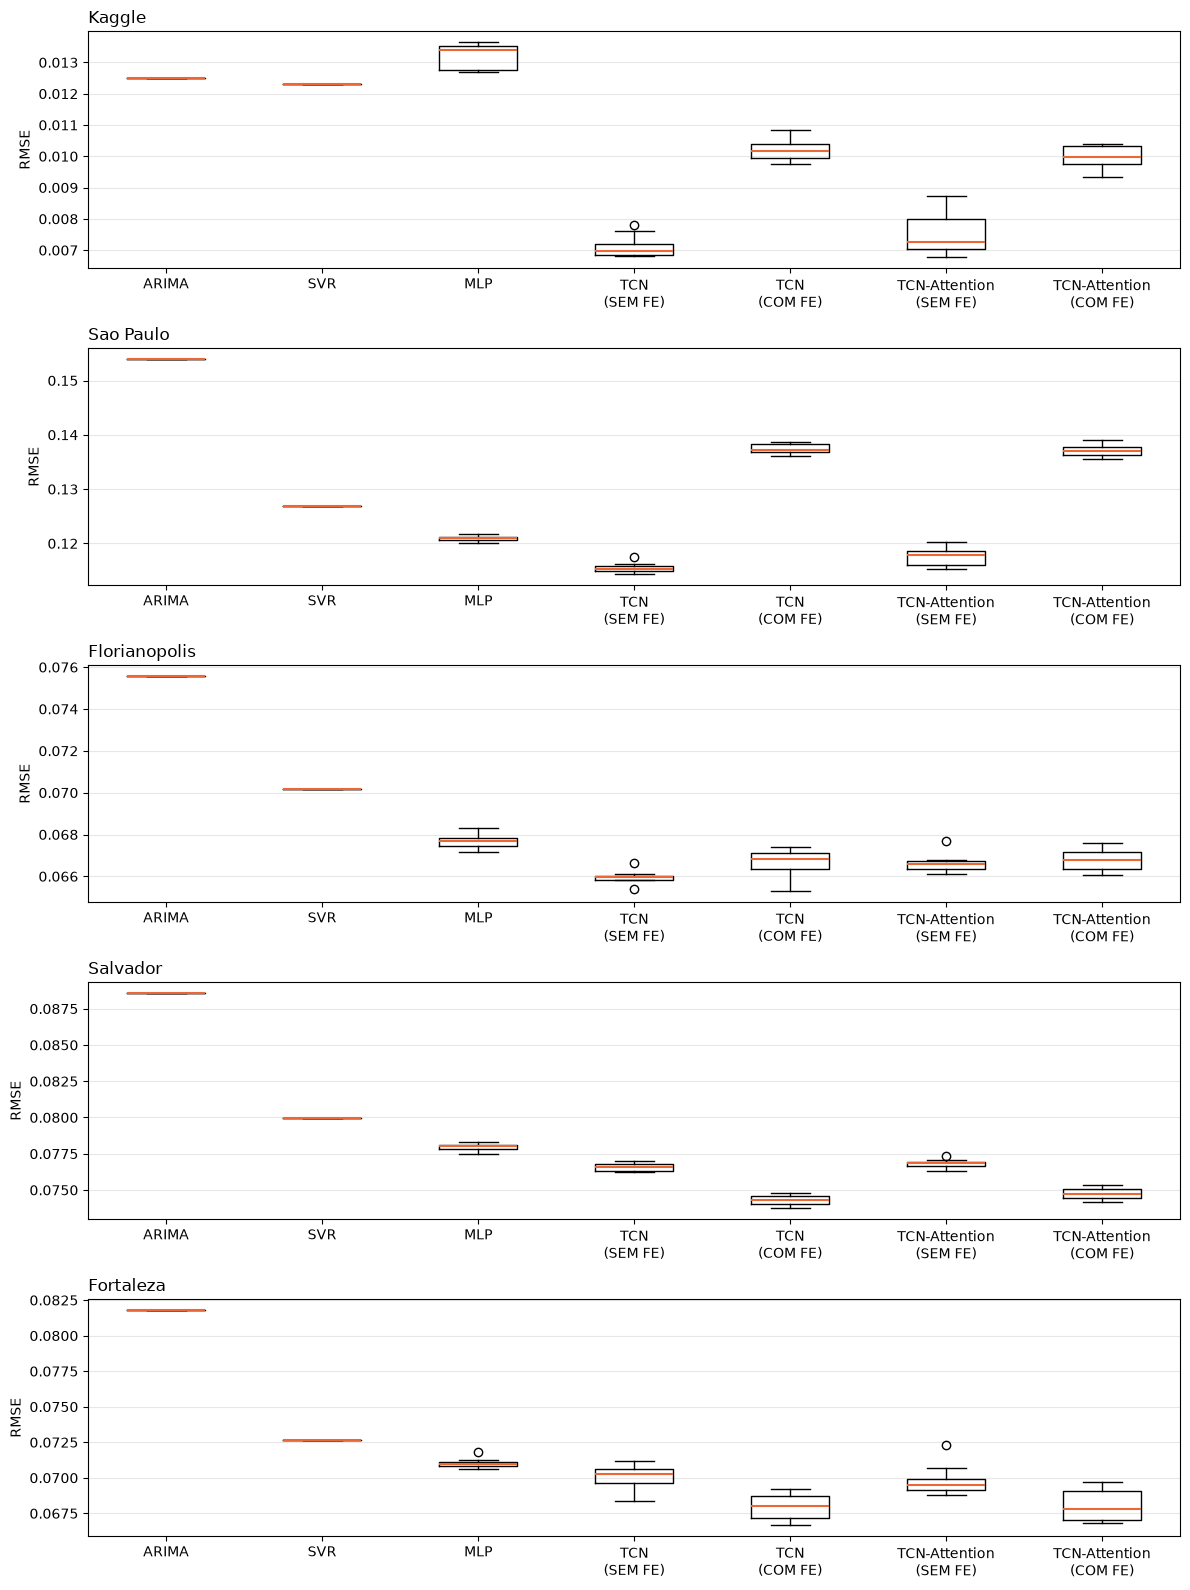

In [19]:
fig, eixos = plt.subplots(len(DATASETS), 1, figsize=(12, 3.2 * len(DATASETS)))
for ax, nome in zip(eixos, DATASETS):
    g = RES[RES.dataset == nome]
    dados_box = [g[g.modelo_cond == m].RMSE.to_numpy() for m in ORDEM]
    ax.boxplot(dados_box, tick_labels=[m.replace(" (", "\n(") for m in ORDEM], widths=0.5,
               medianprops=dict(color="#eb6834", lw=1.5))
    ax.set_title(nome, loc="left"); ax.set_ylabel("RMSE"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(PASTA / "boxplot_rmse.png", dpi=150); plt.show()

## 8. Friedman–Nemenyi: diagrama de distância crítica ([MDPI] Fig. 8; Demšar, 2006)
- **Blocos:** os 5 datasets (N = 5). Este é o uso do teste previsto por Demšar: comparar métodos sobre vários conjuntos de dados.
- **Concorrentes:** os 7 modelos/condições, comparados pelo RMSE médio das 10 execuções.

Friedman χ² = 19.71, p = 0.00311 | Nemenyi CD = 4.03 (k = 7, N = 5)


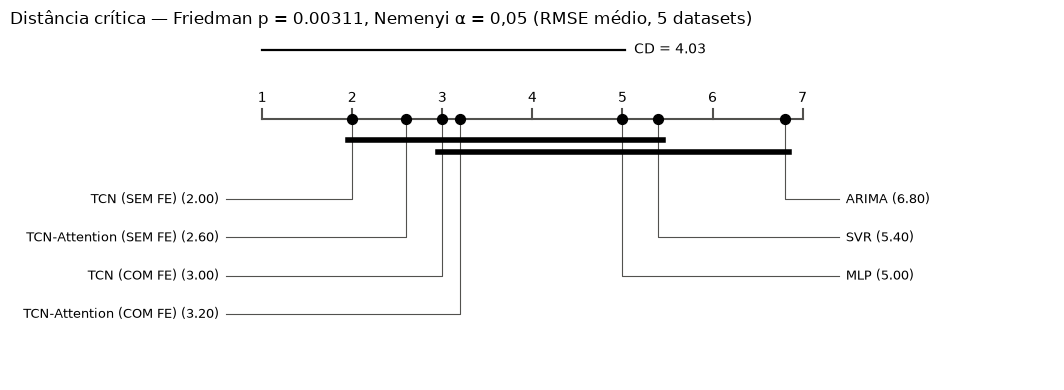

In [20]:
Q_NEMENYI = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728, 6: 2.850, 7: 2.949, 8: 3.031, 9: 3.102, 10: 3.164}   # α = 0,05
B = RES.groupby(["dataset", "modelo_cond"]).RMSE.mean().unstack()[ORDEM]
N, k = B.shape
postos = pd.Series(np.apply_along_axis(rankdata, 1, B.to_numpy()).mean(0), index=B.columns)
chi2, p = friedmanchisquare(*[B[c] for c in B.columns])
CD = Q_NEMENYI[k] * np.sqrt(k * (k + 1) / (6 * N))
print(f"Friedman χ² = {chi2:.2f}, p = {p:.3g} | Nemenyi CD = {CD:.2f} (k = {k}, N = {N})")

ordem = postos.sort_values().index.tolist()
grupos = []
for i, a in enumerate(ordem):
    j = max(jj for jj in range(i, k) if postos[ordem[jj]] - postos[a] < CD)
    if j > i and not any(gi <= i and j <= gj for gi, gj in grupos): grupos.append((i, j))
fig, ax = plt.subplots(figsize=(11, 4)); ax.set_xlim(-1.8, k + 2.8); ax.set_ylim(0, 1); ax.axis("off"); y0 = 0.75
ax.plot([1, k], [y0, y0], color="#52514e")
for t in range(1, k + 1):
    ax.plot([t, t], [y0, y0 + 0.03], color="#52514e"); ax.text(t, y0 + 0.05, str(t), ha="center")
ax.plot([1, 1 + CD], [0.95, 0.95], color="k", lw=1.6); ax.text(1 + CD + 0.1, 0.95, f"CD = {CD:.2f}", va="center")
for idx, c in enumerate(ordem):
    r = postos[c]; esq = idx < (k + 1) // 2
    yl = 0.52 - 0.11 * (idx if esq else k - 1 - idx); xl = 0.6 if esq else k + 0.4
    ax.plot([r, r, xl], [y0, yl, yl], color="#52514e", lw=0.8); ax.scatter([r], [y0], s=50, color="k", zorder=5)
    ax.text(xl + (-0.08 if esq else 0.08), yl, f"{c} ({r:.2f})", ha="right" if esq else "left", va="center", fontsize=9.5)
for gi, (i, j) in enumerate(grupos):
    ax.plot([postos[ordem[i]] - 0.05, postos[ordem[j]] + 0.05], [y0 - 0.06 - 0.035 * gi] * 2, color="k", lw=4)
ax.set_title(f"Distância crítica — Friedman p = {p:.3g}, Nemenyi α = 0,05 (RMSE médio, {N} datasets)", loc="left")
plt.tight_layout(); plt.savefig(PASTA / "distancia_critica.png", dpi=150); plt.show()

## 9. Real × TCN-Attention nos 150 primeiros pontos do teste ([MDPI] Figs. 9–12)
Para cada condição, mostramos a execução com o RMSE mediano, que é a mais representativa das 10.

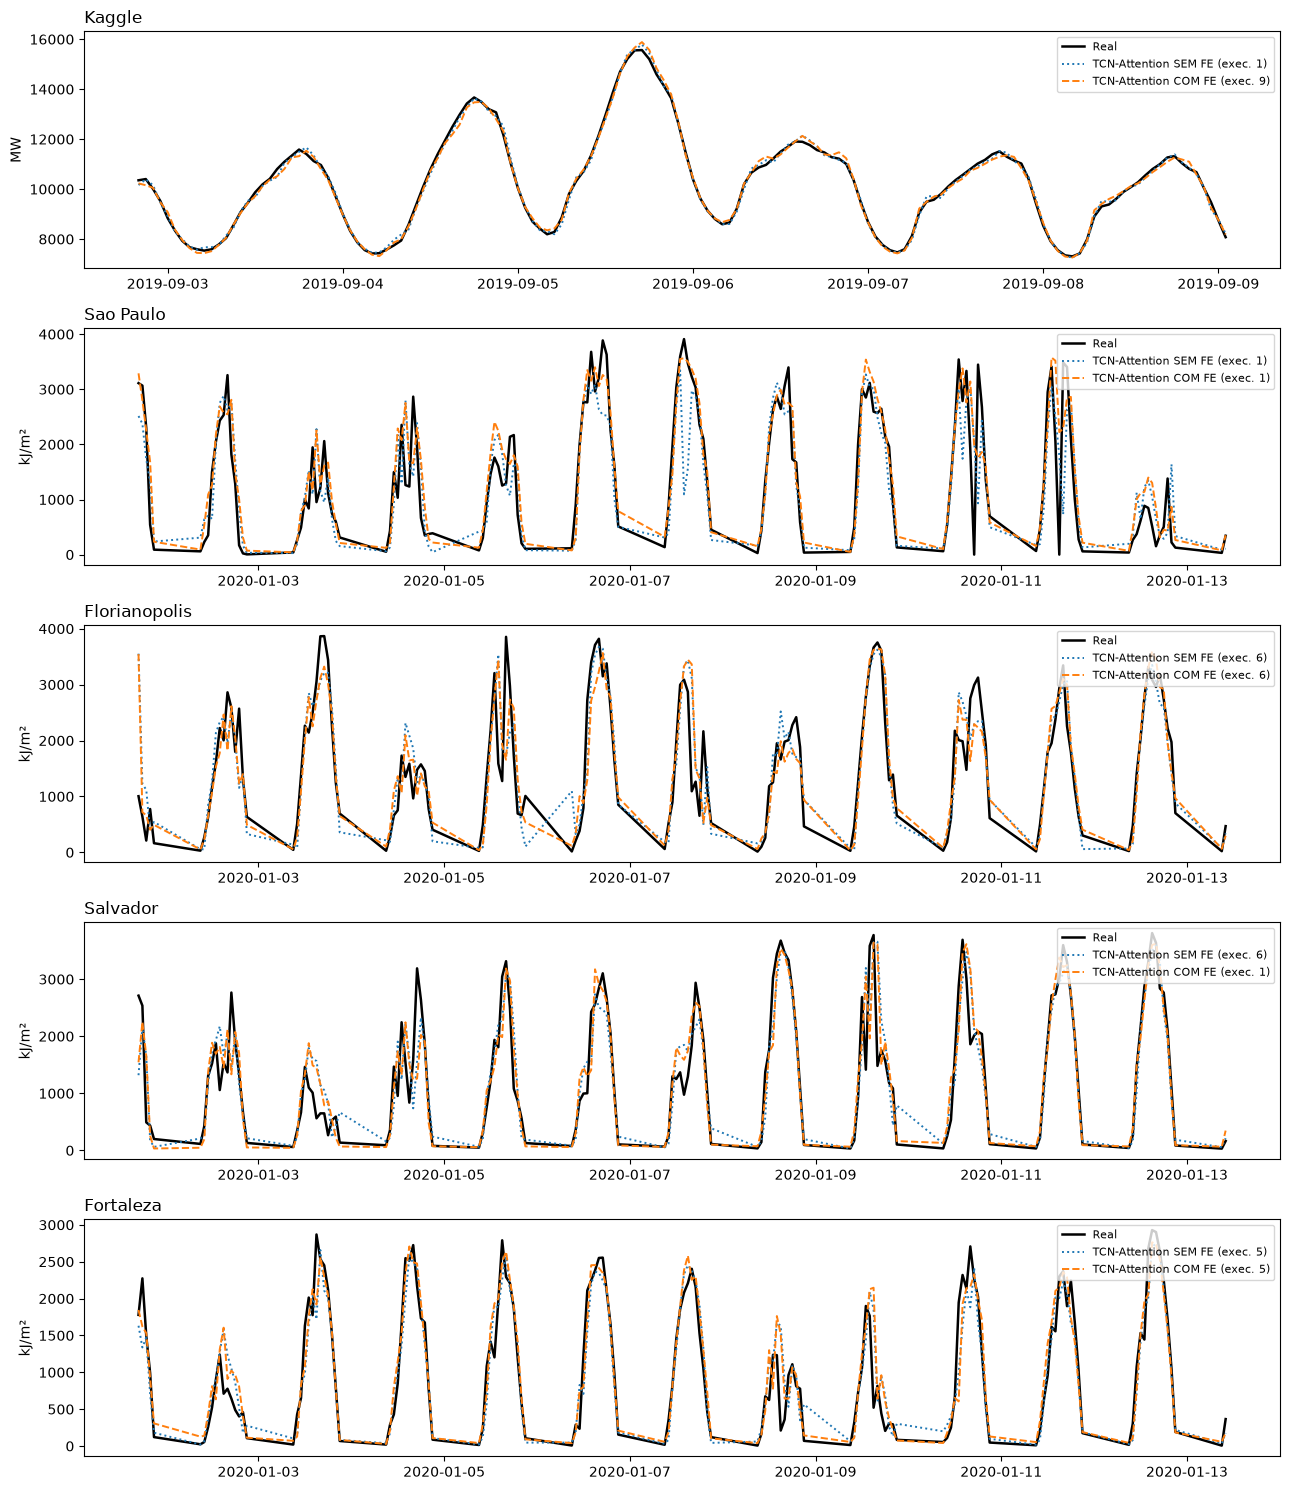

In [21]:
fig, eixos = plt.subplots(len(DATASETS), 1, figsize=(13, 3 * len(DATASETS)))
for ax, nome in zip(eixos, DATASETS):
    d = DATASETS[nome]; real = d["serie"]["actual"].iloc[-d["n_te"]:]
    ax.plot(real.index[:150], real.to_numpy()[:150], color="k", lw=1.8, label="Real")
    for condicao, estilo in [("SEM", ":"), ("COM", "--")]:
        g = RES[(RES.dataset == nome) & (RES.modelo == "TCN-Attention") & (RES.condicao == condicao)].sort_values("RMSE")
        e = int(g.execucao.iloc[len(g) // 2])
        pred = np.load(PASTA / "previsoes" / f"{nome}__TCN-Attention__{condicao}__{e}.npy")
        ax.plot(real.index[:150], pred[:150], ls=estilo, lw=1.4, label=f"TCN-Attention {condicao} FE (exec. {e})")
    ax.set_title(nome, loc="left"); ax.set_ylabel("MW" if nome == "Kaggle" else "kJ/m²"); ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.savefig(PASTA / "forecast_tcn_attention.png", dpi=150); plt.show()